# DSA 2050 Week 1 — Retail Data Analysis

**Problem framing**  
**Stakeholder:** Retail leadership / store operations manager.  
**Decision supported:** Which product should be selected for a small, controlled sales/availability pilot next quarter?  
**Unit of analysis:** One transaction/order record (`OrderID`) in the supplied CSV.  
**Analysis type:** Mainly descriptive, with a prescriptive next-step recommendation.  
**Constraint:** The extract covers one quarter and has no cost, inventory, discount, return, or promotion fields; recorded revenue is not profit and does not establish causality.

This notebook uses relative paths and computes three KPIs plus two labelled charts. Interpretations follow each visualization. Run from the repository root.


## 1. Load and inspect the dataset

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("retail.csv")
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="raise")

# Required initial inspection
display(df.head())
print("Shape (rows, columns):", df.shape)
df.info()

,OrderID,Date,CustomerID,Region,Channel,Category,Product,Quantity,UnitPrice_KES,Revenue_KES,PaymentMethod
0,ORD0001,2026-03-23,CUST032,Mombasa,In-Store,Electronics,Wireless Mouse,3,1800,5400,M-Pesa
1,ORD0002,2026-03-28,CUST005,Nairobi,In-Store,Electronics,Bluetooth Speaker,4,5200,20800,M-Pesa
2,ORD0003,2026-03-06,CUST092,Nakuru,In-Store,Electronics,Bluetooth Speaker,2,5200,10400,Cash
3,ORD0004,2026-02-05,CUST044,Kisumu,In-Store,Electronics,Keyboard,4,3200,12800,Card
4,ORD0005,2026-01-14,CUST046,Kisumu,In-Store,Electronics,Power Bank,1,3500,3500,M-Pesa


Shape (rows, columns): (300, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   OrderID        300 non-null    object        
 1   Date           300 non-null    datetime64[ns]
 2   CustomerID     300 non-null    object        
 3   Region         300 non-null    object        
 4   Channel        300 non-null    object        
 5   Category       300 non-null    object        
 6   Product        300 non-null    object        
 7   Quantity       300 non-null    int64         
 8   UnitPrice_KES  300 non-null    int64         
 9   Revenue_KES    300 non-null    int64         
 10  PaymentMethod  300 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(7)
memory usage: 25.9+ KB


**Dataset description.** The file has **300 rows and 11 columns**. Each row represents one recorded retail transaction/order. It contains identifier/date and categorical fields (`OrderID`, `Date`, `CustomerID`, `Region`, `Channel`, `Category`, `Product`, `PaymentMethod`) and numeric fields (`Quantity`, `UnitPrice_KES`, `Revenue_KES`). `Date` is parsed as a datetime for time-based analysis.


## 2. Diagnostic Python and statistics check

In [2]:
required_columns = {"OrderID", "Date", "CustomerID", "Region", "Channel", "Category", "Product", "Quantity", "UnitPrice_KES", "Revenue_KES", "PaymentMethod"}
assert required_columns.issubset(df.columns), f"Missing columns: {required_columns - set(df.columns)}"
checks = pd.Series({
    "missing_cells": int(df.isna().sum().sum()),
    "duplicate_order_ids": int(df["OrderID"].duplicated().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "quantity_x_price_mismatches": int((df["Quantity"] * df["UnitPrice_KES"] != df["Revenue_KES"]).sum()),
    "nonpositive_quantity": int((df["Quantity"] <= 0).sum()),
    "nonpositive_unit_price": int((df["UnitPrice_KES"] <= 0).sum()),
})
print(checks.to_string())
assert (checks == 0).all(), "At least one data diagnostic failed."
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("\nDescriptive statistics for numeric fields:")
display(df[["Quantity", "UnitPrice_KES", "Revenue_KES"]].describe().round(2))

missing_cells                  0
duplicate_order_ids            0
duplicate_rows                 0
quantity_x_price_mismatches    0
nonpositive_quantity           0
nonpositive_unit_price         0
Date range: 2026-01-01 to 2026-03-31

Descriptive statistics for numeric fields:


,Quantity,UnitPrice_KES,Revenue_KES
count,300.00,300.00,300.00
mean,3.02,3542.33,10688.17
std,1.45,2771.67,11008.09
min,1.00,900.00,900.00
25%,2.00,1500.00,4200.00
50%,3.00,3000.00,7200.00
75%,4.00,4800.00,13500.00
max,5.00,14500.00,72500.00


## 3. Three key performance indicators (KPIs)

In [3]:
transactions = df["OrderID"].nunique()
total_revenue = df["Revenue_KES"].sum()
avg_transaction_value = total_revenue / transactions
kpis = pd.DataFrame([
    {"KPI": "Total revenue", "Calculation": "sum(Revenue_KES)", "Result": f"KES {total_revenue:,.0f}", "Meaning": "Total recorded sales value in this extract; it is not profit."},
    {"KPI": "Number of transactions", "Calculation": "count(unique OrderID)", "Result": f"{transactions:,}", "Meaning": "Count of distinct recorded orders in the period."},
    {"KPI": "Average transaction value", "Calculation": "total revenue / unique transactions", "Result": f"KES {avg_transaction_value:,.2f}", "Meaning": "Average recorded revenue per order; not a customer lifetime value."},
])
display(kpis)

,KPI,Calculation,Result,Meaning
0,Total revenue,sum(Revenue_KES),"KES 3,206,450",Total recorded sales value in this extract; it...
1,Number of transactions,count(unique OrderID),300,Count of distinct recorded orders in the period.
2,Average transaction value,total revenue / unique transactions,"KES 10,688.17",Average recorded revenue per order; not a cust...


## 4. Visualizations

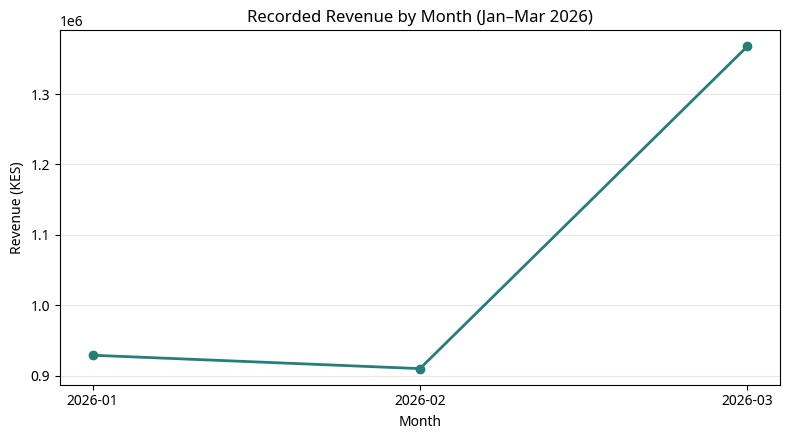

In [4]:
# Plot 1: monthly revenue
df["Month"] = df["Date"].dt.to_period("M").astype(str)
monthly_revenue = df.groupby("Month")["Revenue_KES"].sum().sort_index()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(monthly_revenue.index, monthly_revenue.values, marker="o", linewidth=2, color="#267E78")
ax.set_title("Recorded Revenue by Month (Jan–Mar 2026)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (KES)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretation — monthly revenue.** Revenue is KES 928,900 in January, KES 909,900 in February, and KES 1,367,650 in March. March is higher than February, but three months without promotion, inventory, or seasonality context are not enough to infer a sustained trend or cause.

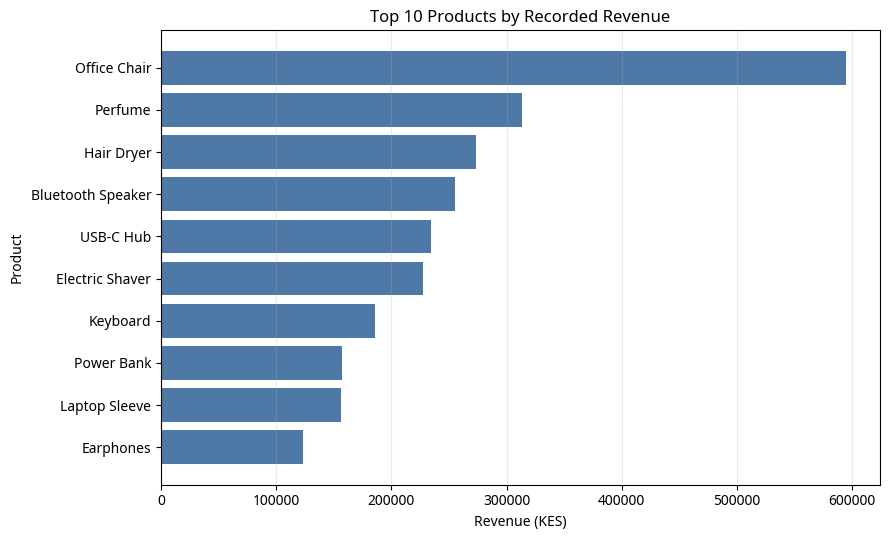

In [5]:
# Plot 2: top 10 products by recorded revenue
product_revenue = df.groupby("Product")["Revenue_KES"].sum().sort_values(ascending=False).head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(product_revenue.index, product_revenue.values, color="#4E79A7")
ax.set_title("Top 10 Products by Recorded Revenue")
ax.set_xlabel("Revenue (KES)")
ax.set_ylabel("Product")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

**Interpretation — product revenue.** Office Chairs lead the top-ten products at KES 594,500, substantially ahead of the next product, Perfume (KES 313,500). Chairs account for 12 orders only; confirm margin and availability and test a limited intervention with a holdout before scaling.

## 5. Short conclusion

The dataset is internally consistent on basic checks and shows Office Chairs as the leading product by recorded revenue. A controlled, one-month chair merchandising/availability pilot is a reasonable hypothesis to test, not a proven growth opportunity. Evaluate incremental gross profit against a holdout and review stock-outs, returns, discounts, and possible cannibalization before deciding whether to scale.

**Limitations:** One quarter of transaction data; no costs/margins, stock levels, discounts, returns, promotion exposure, or causal design. The data cannot show whether chair sales are profitable, whether demand was constrained, or whether March growth will continue.

## Reproducibility

Install `requirements.txt`, then launch Jupyter from the project root. `retail.csv` is loaded via the relative path `Path("retail.csv")`.